# ParFlow-CLM vs SNOTEL Comparison

Load model output from Notebook 2, fetch SNOTEL observations, and evaluate:
- Daily SWE time series (obs vs. model)
- Scatter plot with 1:1 line
- Metrics: NSE, RMSE, |bias|%, peak SWE bias, melt-out day delta
- CW3E precipitation vs. SNOTEL precipitation (forcing quality check)


In [2]:
import os
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import hf_hydrodata as hf
from pathlib import Path
from datetime import datetime

sys.path.insert(0, os.path.abspath(".."))
from helpers import read_site_config

# HydroData PIN (persists from Notebook 1)
hf.register_api_pin("lt0663@princeton.edu", "0601")


In [29]:
IBM_BLUE = "#648FFF"
IBM_PINK = "#DC267F"
IBM_ORANGE = "#FE6100"
IBM_YELLOW = "#FFB000"
IBM_PURPLE = "#785EF0"

In [12]:
def load_pfclm(static_write_dir):
    run_dir = Path(static_write_dir)
    cfg = read_site_config(run_dir / "site_config.txt")

    site_name  = cfg["site_name"]
    water_year = int(cfg["water_year"])
    start      = cfg["start"]
    end        = cfg["end"]
    triplet    = cfg["triplet"]
    region     = cfg["region"]

    print(f"Site: {site_name} ({region}), WY{water_year}, triplet={triplet}")

    clm_files = sorted(run_dir.glob("*.out.CLM.*.nc"))
    if not clm_files:
        raise FileNotFoundError(f"No CLM output in {run_dir}. Run Notebook 2 first.")

    clm_ds = xr.open_dataset(clm_files[0])
    if "swe_out" not in clm_ds:
        raise KeyError(f"swe_out not in CLM output. Variables: {list(clm_ds.data_vars)}")

    swe_h = clm_ds["swe_out"].values.flatten()
    dt_start = datetime.strptime(start, "%Y-%m-%d")
    hourly_dates = pd.date_range(dt_start, periods=len(swe_h), freq="h")
    

    model_swe_hourly = pd.Series(swe_h, index=hourly_dates, name="model_swe_mm")
    model_swe_daily  = model_swe_hourly.resample("D").mean()

    print(f"Loaded {len(swe_h)} hourly SWE values ({len(model_swe_daily)} days)")
    print(f"  Peak model SWE: {model_swe_daily.max():.0f} mm")

    return clm_ds, cfg, model_swe_hourly, model_swe_daily, hourly_dates

    

In [21]:
# ============================================================
# Load all the different runs
# ============================================================
PFCLM_DEFAULT_PATH = "/workspaces/single_column_PFCLM/runs/snow/Berthoud_Summit_WY2024_001"
PFCLM_IMPROVED_PATH = "/workspaces/single_column_PFCLM/runs/snow/Berthoud_Summit_WY2024_SZA"

print("=======================")
print("Default (z_sno = 0.01)")
print("=======================")
dflt_clm_ds, dflt_cfg, dflt_model_swe_hourly, dflt_model_swe_daily, dflt_hourly_dates = load_pfclm(PFCLM_DEFAULT_PATH)

print("\n================================")
print("Improved (solar zenith z_sno)")
print("================================")
imprv_clm_ds, imprv_cfg, imprv_model_swe_hourly, imprv_model_swe_daily, imprv_hourly_dates = load_pfclm(PFCLM_IMPROVED_PATH)

# set the cfg on one of these since these features wont change for the same site and water year
site_name  = dflt_cfg["site_name"]
water_year = int(dflt_cfg["water_year"])
start      = dflt_cfg["start"]
end        = dflt_cfg["end"]
triplet    = dflt_cfg["triplet"]
region     = dflt_cfg["region"]

print(f"\nSite: {site_name} ({region}), WY{water_year}, triplet={triplet}")

Default (z_sno = 0.01)
Site: Berthoud_Summit (Colorado Rockies), WY2024, triplet=335:CO:SNTL
Loaded 8784 hourly SWE values (366 days)
  Peak model SWE: 633 mm

Improved (solar zenith z_sno)
Site: Berthoud_Summit (Colorado Rockies), WY2024, triplet=335:CO:SNTL
Loaded 8784 hourly SWE values (366 days)
  Peak model SWE: 658 mm

Site: Berthoud_Summit (Colorado Rockies), WY2024, triplet=335:CO:SNTL


In [22]:
# ============================================================
# Fetch SNOTEL SWE observations
# ============================================================
df = hf.get_point_data(
    dataset="snotel", variable="swe",
    temporal_resolution="daily", aggregation="sod",
    site_ids=[triplet],
    date_start=start, date_end=end,
)

if df is None or df.empty or triplet not in df.columns:
    raise RuntimeError(f"No SNOTEL SWE data for triplet {triplet}")

obs_dates = pd.to_datetime(df["date"])
obs_swe_daily = pd.Series(df[triplet].values.astype(float),
                          index=pd.DatetimeIndex(obs_dates),
                          name="obs_swe_mm").dropna()
# SNOTEL SWE is already in mm — do NOT apply any unit conversion
print(f"SNOTEL SWE: {len(obs_swe_daily)} daily values, peak={obs_swe_daily.max():.0f} mm")


SNOTEL SWE: 366 daily values, peak=610 mm


In [35]:
# ============================================================
# Compute metrics on common dates
# ============================================================
def compute_metrics(model_swe_daily, obs_swe_daily):
    common = obs_swe_daily.index.intersection(model_swe_daily.index)
    obs_c = obs_swe_daily.loc[common]
    mod_c = model_swe_daily.loc[common]
    mask = (~obs_c.isna()) & (~mod_c.isna())
    obs_c = obs_c[mask]
    mod_c = mod_c[mask]

    # Basic error stats
    bias  = float((mod_c - obs_c).mean())
    rmse  = float(np.sqrt(((mod_c - obs_c) ** 2).mean()))
    peak_obs = float(obs_c.max())
    peak_mod = float(mod_c.max())
    bias_pct = (peak_mod - peak_obs) / peak_obs * 100.0 if peak_obs > 0 else np.nan

    # Nash-Sutcliffe
    mu_o    = obs_c.mean()
    ss_res  = ((mod_c - obs_c) ** 2).sum()
    ss_tot  = ((obs_c - mu_o) ** 2).sum()
    nse     = float(1 - ss_res / ss_tot) if ss_tot > 0 else np.nan

    # Peak SWE dates
    peak_obs_date = obs_c.idxmax()
    peak_mod_date = mod_c.idxmax()
    peak_date_delta = (peak_mod_date - peak_obs_date).days

    # Melt-out date (first day SWE < 10 mm after peak)
    def melt_out(s, threshold=10.0):
        spring = s[s.index >= pd.Timestamp(f"{water_year}-02-01")]
        if spring.empty:
            return None
        peak_idx = spring.idxmax()
        post = spring[spring.index >= peak_idx]
        below = post[post < threshold]
        return below.index[0] if not below.empty else None

    mo_obs = melt_out(obs_c)
    mo_mod = melt_out(mod_c)
    mo_delta = (mo_mod - mo_obs).days if (mo_obs and mo_mod) else None

    print(f"\n{'='*55}")
    print(f"  {site_name} WY{water_year} — SWE Comparison")
    print(f"{'='*55}")
    print(f"  N days:            {len(obs_c)}")
    print(f"  Mean bias:         {bias:+.1f} mm")
    print(f"  RMSE:              {rmse:.1f} mm")
    print(f"  NSE:               {nse:.3f}")
    print(f"  Peak SWE obs:      {peak_obs:.0f} mm on {peak_obs_date.date()}")
    print(f"  Peak SWE model:    {peak_mod:.0f} mm on {peak_mod_date.date()}")
    print(f"  Peak |bias|%:      {abs(bias_pct):.1f}%")
    print(f"  Peak date delta:   {peak_date_delta:+d} days")
    if mo_delta is not None:
        print(f"  Obs melt-out:      {mo_obs.date()}")
        print(f"  Model melt-out:    {mo_mod.date()}")
        print(f"  Melt-out delta:    {mo_delta:+d} days")
    else:
        print(f"  Melt-out:          not reached in this period")
    print(f"{'='*55}")

    metrics = {
        "site_name": site_name,
        "water_year": water_year,
        "n_days": int(len(obs_c)),
        "mean_bias_mm": bias,
        "rmse_mm": rmse,
        "nse": nse,
        "peak_swe_obs_mm": peak_obs,
        "peak_swe_obs_date": peak_obs_date.date(),
        "peak_swe_model_mm": peak_mod,
        "peak_swe_model_date": peak_mod_date.date(),
        "peak_abs_bias_pct": float(abs(bias_pct)) if not np.isnan(bias_pct) else np.nan,
        "peak_date_delta_days": peak_date_delta,
        "obs_melt_out_date": mo_obs.date() if mo_obs is not None else None,
        "model_melt_out_date": mo_mod.date() if mo_mod is not None else None,
        "mo_delta": mo_delta,
        "mod_c" : mod_c,
        "obs_c" : obs_c,
        "mo_obs" : mo_obs,
        "mo_mod" : mo_mod
    }

    return metrics


In [36]:

print("Default (z_sno = 0.01)")
#dflt_clm_ds, dflt_cfg, dflt_model_swe_hourly, dflt_model_swe_daily, dflt_hourly_dates = load_pfclm(PFCLM_DEFAULT_PATH)
dflt_metrics = compute_metrics(dflt_model_swe_daily, obs_swe_daily)

print("Improved (solar zenith z_sno)")
#imprv_clm_ds, imprv_cfg, imprv_model_swe_hourly, imprv_model_swe_daily, imprv_hourly_dates = load_pfclm(PFCLM_IMPROVED_PATH)
imprv_metrics = compute_metrics(imprv_model_swe_daily, obs_swe_daily)

Default (z_sno = 0.01)

  Berthoud_Summit WY2024 — SWE Comparison
  N days:            365
  Mean bias:         +1.6 mm
  RMSE:              96.4 mm
  NSE:               0.811
  Peak SWE obs:      610 mm on 2024-04-29
  Peak SWE model:    633 mm on 2024-05-19
  Peak |bias|%:      3.9%
  Peak date delta:   +20 days
  Obs melt-out:      2024-06-12
  Model melt-out:    2024-07-02
  Melt-out delta:    +20 days
Improved (solar zenith z_sno)

  Berthoud_Summit WY2024 — SWE Comparison
  N days:            365
  Mean bias:         +11.3 mm
  RMSE:              116.3 mm
  NSE:               0.724
  Peak SWE obs:      610 mm on 2024-04-29
  Peak SWE model:    658 mm on 2024-05-28
  Peak |bias|%:      7.9%
  Peak date delta:   +29 days
  Obs melt-out:      2024-06-12
  Model melt-out:    2024-07-07
  Melt-out delta:    +25 days


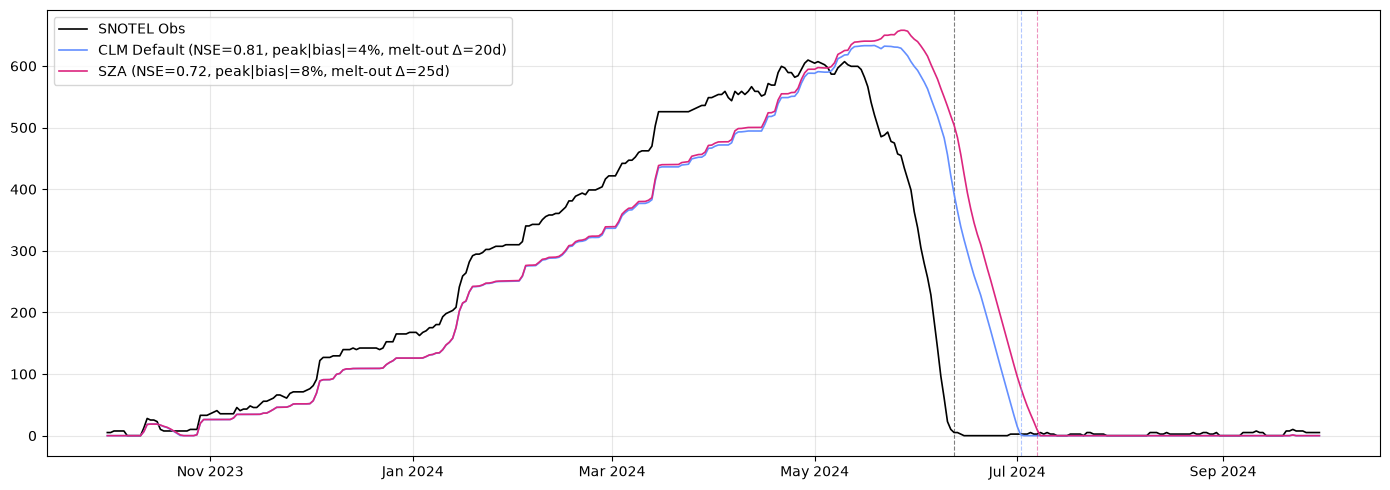

In [40]:
# ============================================================
# Time Series Plot — Daily SWE
# ============================================================
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(dflt_metrics["obs_c"].index, dflt_metrics["obs_c"].values, color="black",  lw=1.2, label="SNOTEL Obs")

if dflt_metrics["mo_obs"] is not None:
    ax.axvline(dflt_metrics["mo_obs"], color="black",   ls="--", lw=0.8, alpha=0.5)

lab_dflt = f"CLM Default (NSE={dflt_metrics['nse']:.2f}, peak|bias|={dflt_metrics['peak_abs_bias_pct']:.0f}%, melt-out Δ={dflt_metrics['mo_delta'] if dflt_metrics['mo_delta'] is not None else 'NA'}d)"
lab_imprv = f"SZA (NSE={imprv_metrics['nse']:.2f}, peak|bias|={abs(imprv_metrics['peak_abs_bias_pct']):.0f}%, melt-out Δ={imprv_metrics['mo_delta'] if imprv_metrics['mo_delta'] is not None else 'NA'}d)"

ax.plot(dflt_metrics["mod_c"].index, dflt_metrics["mod_c"].values, color=IBM_BLUE, lw=1.2, label=lab_dflt)
ax.plot(imprv_metrics["mod_c"].index, imprv_metrics["mod_c"].values, color=IBM_PINK, lw=1.2, label=lab_imprv)

if dflt_metrics["mo_mod"] is not None:
    ax.axvline(dflt_metrics["mo_mod"], color=IBM_BLUE, ls="--", lw=0.8, alpha=0.5)
if imprv_metrics["mo_mod"] is not None:
    ax.axvline(imprv_metrics["mo_mod"], color=IBM_PINK, ls="--", lw=0.8, alpha=0.5)


ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


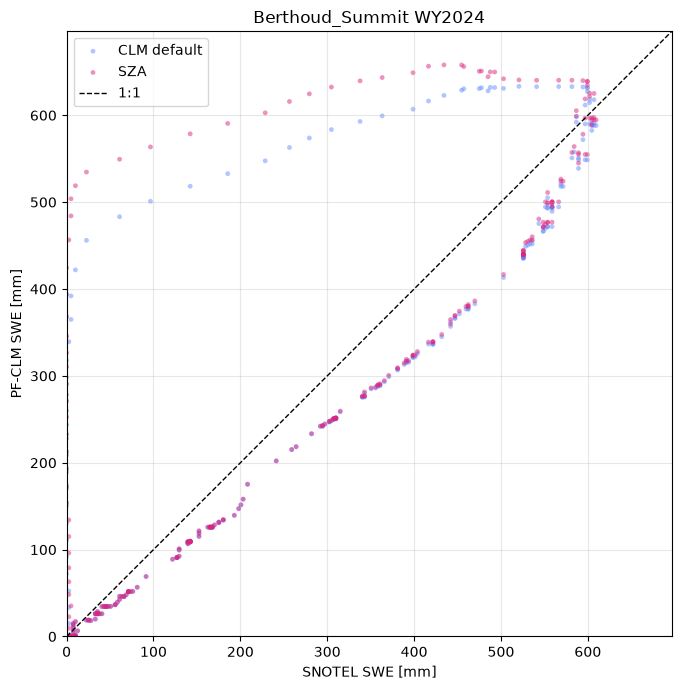

In [41]:
# ============================================================
# Scatter Plot — Observed vs Modeled
# ============================================================
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(dflt_metrics["obs_c"].values, dflt_metrics["mod_c"].values, s=12, alpha=0.5, color=IBM_BLUE, edgecolors="none", label='CLM default')
ax.scatter(dflt_metrics["obs_c"].values, imprv_metrics["mod_c"].values, s=12, alpha=0.5, color=IBM_PINK, edgecolors="none", label='SZA')

lim_max = max(dflt_metrics["obs_c"].max(), dflt_metrics["mod_c"].max()) * 1.1
ax.plot([0, lim_max], [0, lim_max], "k--", lw=1, label="1:1")
ax.set_xlim(0, lim_max)
ax.set_ylim(0, lim_max)
ax.set_xlabel("SNOTEL SWE [mm]")
ax.set_ylabel("PF-CLM SWE [mm]")
ax.set_title(f"{site_name} WY{water_year}")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


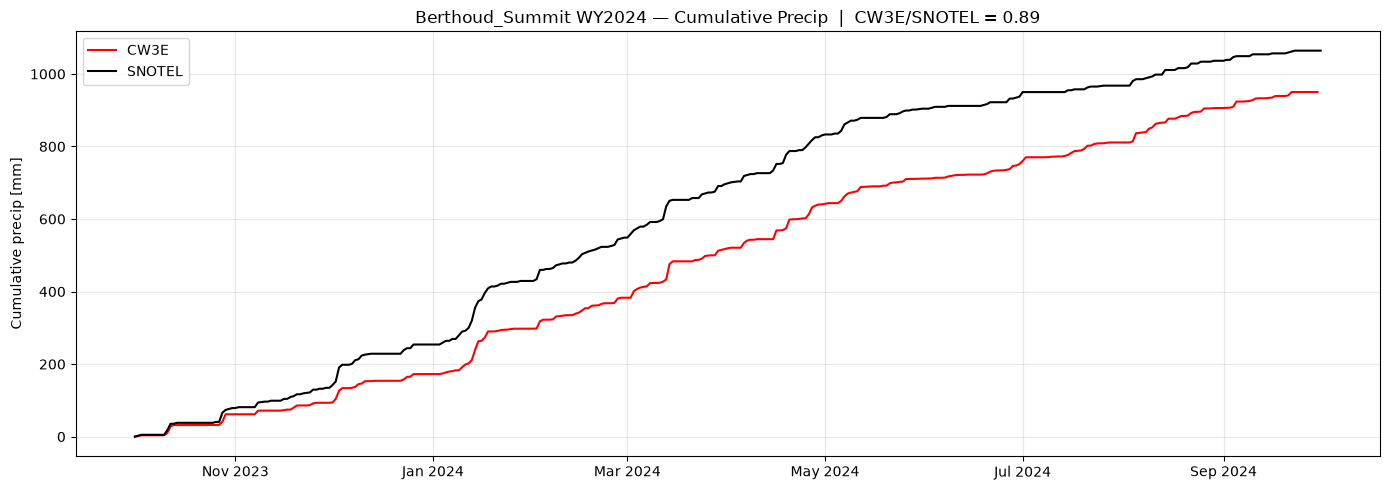

In [43]:
# ============================================================
# Forcing Quality — CW3E vs SNOTEL Precipitation
# ============================================================
# SNOTEL precip (daily totals, already mm) vs CW3E precip (cumulative).
# CW3E is typically high-biased in the mountains — check the scale.

def forcing_quality(run_path, cfg):
    run_dir = Path(run_path)
    forcing_path = run_dir / cfg["forcing_file"]
    forcing_raw  = np.loadtxt(forcing_path)
    forc_dates   = pd.date_range(start, periods=len(forcing_raw), freq="h")

    # CW3E precip is mm/s -> convert to mm/hr then daily sum
    cw3e_precip_hourly = pd.Series(forcing_raw[:, 2] * 3600, index=forc_dates, name="cw3e_precip_mm")
    cw3e_precip_daily  = cw3e_precip_hourly.resample("D").sum()
    cw3e_precip_cum    = cw3e_precip_daily.cumsum()

    # SNOTEL precip
    try:
        df = hf.get_point_data(
            dataset="snotel", variable="precipitation",
            temporal_resolution="daily", aggregation="sum",
            site_ids=[triplet],
            date_start=start, date_end=end,
        )
        if df is not None and not df.empty and triplet in df.columns:
            snotel_precip_daily = pd.Series(df[triplet].values.astype(float),
                                            index=pd.to_datetime(df["date"]),
                                            name="snotel_precip_mm").dropna()
            # SNOTEL precip is already in mm
            snotel_precip_cum = snotel_precip_daily.cumsum()
        else:
            snotel_precip_cum = None
    except Exception as e:
        print(f"SNOTEL precip fetch failed: {e}")
        snotel_precip_cum = None

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(cw3e_precip_cum.index, cw3e_precip_cum.values, color="red", lw=1.5, label="CW3E")
    if snotel_precip_cum is not None:
        ax.plot(snotel_precip_cum.index, snotel_precip_cum.values, color="black",
                lw=1.5, label="SNOTEL")
        ratio = cw3e_precip_cum.iloc[-1] / snotel_precip_cum.iloc[-1] if snotel_precip_cum.iloc[-1] > 0 else np.nan
        ax.set_title(f"{site_name} WY{water_year} — Cumulative Precip  |  "
                    f"CW3E/SNOTEL = {ratio:.2f}")
    else:
        ax.set_title(f"{site_name} WY{water_year} — CW3E Cumulative Precip (no SNOTEL precip)")

    ax.set_ylabel("Cumulative precip [mm]")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
    ax.legend(loc="upper left")
    ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

    return cw3e_precip_cum, snotel_precip_cum

forcing_bthd_sum_wy2024, snotel_bthd_sum_wy2024 = forcing_quality(PFCLM_DEFAULT_PATH, dflt_cfg)


In [ ]:
# ============================================================
# SWE:P curve
# ============================================================
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(dflt_metrics["obs_c"].values, dflt_metrics["mod_c"].values, s=12, alpha=0.5, color=IBM_BLUE, edgecolors="none", label='CLM default')
ax.scatter(dflt_metrics["obs_c"].values, imprv_metrics["mod_c"].values, s=12, alpha=0.5, color=IBM_PINK, edgecolors="none", label='SZA')

lim_max = max(dflt_metrics["obs_c"].max(), dflt_metrics["mod_c"].max()) * 1.1
ax.plot([0, lim_max], [0, lim_max], "k--", lw=1, label="1:1")
ax.set_xlim(0, lim_max)
ax.set_ylim(0, lim_max)
ax.set_xlabel("SNOTEL SWE [mm]")
ax.set_ylabel("PF-CLM SWE [mm]")
ax.set_title(f"{site_name} WY{water_year}")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
